# Objectifs d'apprentissage – Semaine 6

À l'issue de cette semaine, l'étudiant sera capable de :

- **Comprendre** le passage du domaine temporel au domaine fréquentiel.
- **Définir** les séries de Fourier pour les signaux périodiques.
- **Appliquer** la transformée de Fourier à temps discret (DTFT) pour l'analyse spectrale.
- **Interpréter** un spectre de fréquences (amplitude, phase).
- **Visualiser** le spectre d'un signal à l'aide de la FFT.
- **Analyser** l'effet du fenêtrage sur la résolution spectrale.
- **Utiliser** Python pour effectuer des analyses spectrales sur des signaux réels (audio, synthétiques).
- **Concevoir** un analyseur de spectre simple et l'appliquer à un vrai fichier audio.

# 0. Glossaire des acronymes utilisés

| Acronyme | Signification (anglais) | Signification (français) |
|---|---|---|
| **DSP** | Digital Signal Processing | Traitement Numérique du Signal |
| **TF** | Fourier Transform | Transformée de Fourier |
| **SF** | Fourier Series | Série de Fourier |
| **DTFT** | Discrete-Time Fourier Transform | Transformée de Fourier à Temps Discret (TFTD) |
| **DFT** | Discrete Fourier Transform | Transformée de Fourier Discrète (TFD) |
| **FFT** | Fast Fourier Transform | Transformée de Fourier Rapide (TFR) |
| **STFT** | Short-Time Fourier Transform | Transformée de Fourier à Court Terme |
| **LTI** | Linear Time-Invariant | Linéaire et Invariant dans le Temps |
| **SNR** | Signal-to-Noise Ratio | Rapport Signal / Bruit |
| **EQM** | — | Erreur Quadratique Moyenne (MSE) |
| **DC** | Direct Current | Composante continue (fréquence nulle) |
| **Hz** | Hertz | Hertz (cycles par seconde) |
| **rad** | Radian | Radian (1 tour = 2π rad) |
| **ADC** | Analog-to-Digital Converter | Convertisseur Analogique-Numérique |
| **ECG** | Electrocardiogram | Électrocardiogramme |
| **WAV** | Waveform Audio File Format | Format de fichier audio PCM |

> **Conventions** :
> - $x[n]$ : signal à temps discret
> - $X(e^{j\omega})$ : transformée de Fourier à temps discret (DTFT) de $x[n]$
> - $X[k]$ : transformée de Fourier discrète (DFT) de longueur $N$
> - $f_s$ : fréquence d'échantillonnage (Hz)
> - $\omega = 2\pi f / f_s$ : pulsation normalisée (rad/éch.)

# 1. Pourquoi la transformée de Fourier ? À quoi sert-elle ?

## 1.1 Le problème posé

Un signal à temps discret $x[n]$ nous donne une information **temporelle** : « quelle est la valeur du signal à l'instant $n$ ? ».

Mais beaucoup de questions d'ingénieur n'ont **pas de réponse simple** dans le domaine temporel :

- *Quelles fréquences sont présentes dans ce signal ?*
- *Y a-t-il un bruit à 50 Hz dans mon enregistrement ECG ?*
- *Le signal de ma voix contient-il un pic à 1 kHz ?*
- *Comment concevoir un filtre qui coupe les basses fréquences ?*

Regarder $x[n]$ directement ne permet pas de répondre à ces questions.

## 1.2 L'idée : décomposer en sinusoïdes

La **transformée de Fourier** est une **projection** du signal sur une base de sinusoïdes complexes $e^{j\omega n}$. Elle répond à la question :

> **« Quelle est l'amplitude et la phase de la sinusoïde de fréquence $\omega$ présente dans mon signal ? »**

Mathématiquement :
$$ X(e^{j\omega}) = \sum_{n=-\infty}^{+\infty} x[n] \, e^{-j\omega n} $$

## 1.3 Analogies : du temps vers la fréquence

| Domaine temporel | Domaine fréquentiel |
|---|---|
| $x[n]$ : signal | $X(e^{j\omega})$ : spectre |
| Somme / intégrale | Produit de convolution → produit simple |
| Durée du signal | Largeur du spectre |
| Échantillons discrets | Fréquences continues (DTFT) ou discrètes (DFT) |

## 1.4 Analogie pédagogique

> Imaginez un **prisme** qui décompose la lumière blanche en couleurs. La transformée de Fourier joue le même rôle pour un signal : elle sépare ses **composantes fréquentielles** comme un prisme sépare les couleurs.

## 1.5 Famille des transformées de Fourier

| Transformée | Signal d'entrée | Résultat |
|---|---|---|
| **Série de Fourier (SF)** | Périodique continu | Spectre de raies |
| **Transformée de Fourier (TF)** | Continu apériodique | Spectre continu |
| **DTFT (TFTD)** | Discret apériodique | Spectre continu périodique |
| **DFT (TFD)** | Discret périodique | Spectre discret périodique |
| **FFT** | Idem DFT (algorithme rapide) | Idem DFT |

**Notre cas** : signaux échantillonnés (donc discrets) et de durée finie (donc périodiques par extension) → nous utilisons la **DFT** implémentée par la **FFT**.

## 1.6 Applications concrètes

1. **Analyse audio** : reconnaissance musicale, égaliseurs, détection de notes.
2. **Télécoms** : modulation OFDM (WiFi, 4G/5G).
3. **Imagerie médicale** : IRM, scanner, ECG.
4. **Radar / sonar** : détection de cibles.
5. **Compression** : MP3, JPEG.
6. **Diagnostic industriel** : analyse vibratoire des machines.

## 1.7 Limites

- La transformée de Fourier **globalise** l'information : elle perd la localisation temporelle.
- Pour conserver les deux, on utilise des variantes : **STFT (spectrogramme)**, **ondelettes**.
- La **FFT** suppose une périodicité du signal → effet de fuite spectrale (leakage) qu'on atténue par fenêtrage.

---

# 2. Rappels théoriques

## 2.1 Série de Fourier (rappel)

Tout signal périodique $x(t)$ de période $T$ peut être décomposé en une somme de sinusoïdes complexes :
$$ x(t) = \sum_{k=-\infty}^{\infty} c_k \, e^{j k \omega_0 t}, \qquad \omega_0 = \frac{2\pi}{T} $$

avec les coefficients :
$$ c_k = \frac{1}{T} \int_{T} x(t) e^{-j k \omega_0 t} \, dt $$

**Interprétation** : tout signal périodique est une somme de sinusoïdes dont les fréquences sont des multiples de $f_0 = 1/T$.

## 2.2 DTFT (Transformée de Fourier à Temps Discret)

Pour une séquence $x[n]$ :
$$ X(e^{j\omega}) = \sum_{n=-\infty}^{+\infty} x[n] \, e^{-j\omega n}, \qquad \omega \in [-\pi, \pi] $$

**Propriétés clés** :
- **Périodicité** : $X(e^{j(\omega + 2\pi)}) = X(e^{j\omega})$
- **Transformée inverse** : $x[n] = \dfrac{1}{2\pi} \int_{-\pi}^{\pi} X(e^{j\omega}) e^{j\omega n} \, d\omega$
- **Linéarité, décalage temporel, convolution** : analogues à la transformée en Z mais sur le cercle unité $z = e^{j\omega}$.

## 2.3 DFT (Transformée de Fourier Discrète)

Pour un signal de durée finie $x[n]$ avec $n = 0, \dots, N-1$ :
$$ X[k] = \sum_{n=0}^{N-1} x[n] \, e^{-j 2\pi k n / N}, \qquad k = 0, \dots, N-1 $$

Transformée inverse :
$$ x[n] = \frac{1}{N} \sum_{k=0}^{N-1} X[k] \, e^{j 2\pi k n / N} $$

**Lien DTFT ↔ DFT** : la DFT est un **échantillonnage** de la DTFT à $\omega_k = 2\pi k/N$.

## 2.4 FFT (Transformée de Fourier Rapide)

La FFT est un **algorithme** qui calcule la DFT en $O(N \log N)$ au lieu de $O(N^2)$. C'est l'un des algorithmes les plus importants de l'ingénierie moderne (Cooley-Tukey, 1965).

**Contrainte** : $N$ est typiquement une puissance de 2 (ou un nombre très composé).

## 2.5 Interprétation du spectre

Pour un signal échantillonné à $f_s$ sur $N$ points, la FFT renvoie $N$ valeurs complexes :

- Les indices $k = 0, \dots, N/2$ correspondent à $f = 0$ à $f_s/2$ (fréquences positives)
- Les indices $k = N/2, \dots, N-1$ correspondent à $f = -f_s/2$ à 0 (fréquences négatives)
- Résolution fréquentielle : $\Delta f = f_s / N$

Pour un signal réel, le spectre est **symétrique** : on ne trace que la moitié positive.

## 2.6 Fenêtrage

En pratique, on n'analyse qu'un **extrait** du signal (N échantillons). Cela revient à multiplier le signal par une **fenêtre rectangulaire**, ce qui introduit des **fuites spectrales (leakage)**.

**Fenêtres classiques** :

| Fenêtre | Largeur du lobe principal | Niveau lobe secondaire |
|---|---|---|
| Rectangulaire | Étroit | −13 dB |
| Hamming | Moyen | −43 dB |
| Hanning | Moyen | −32 dB |
| Blackman | Large | −58 dB |
| Flat-top | Très large | −90 dB |

**Compromis** : résolution vs fuites. Un lobe principal étroit = meilleure résolution, mais lobes secondaires élevés.

## 2.7 Théorème de Parseval

L'énergie totale se conserve entre les deux domaines :
$$ \sum_{n=0}^{N-1} |x[n]|^2 = \frac{1}{N} \sum_{k=0}^{N-1} |X[k]|^2 $$

Utile pour vérifier l'exactitude d'une FFT.

---

# 3. Démonstrations Python

## 3.1 Synthèse de Fourier – Signal carré

Nous allons **synthétiser** un signal carré à partir de ses harmoniques. C'est l'opération **inverse** de l'analyse spectrale.

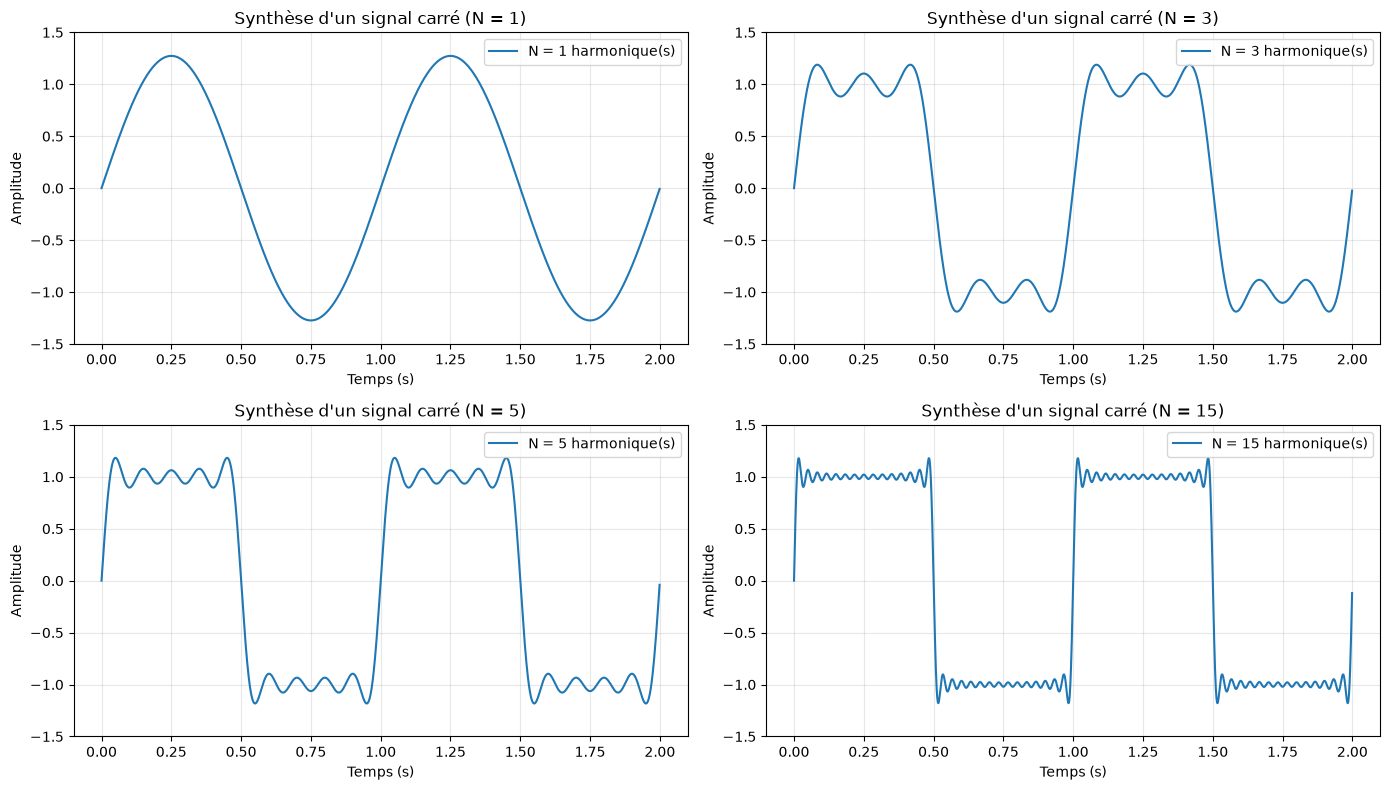

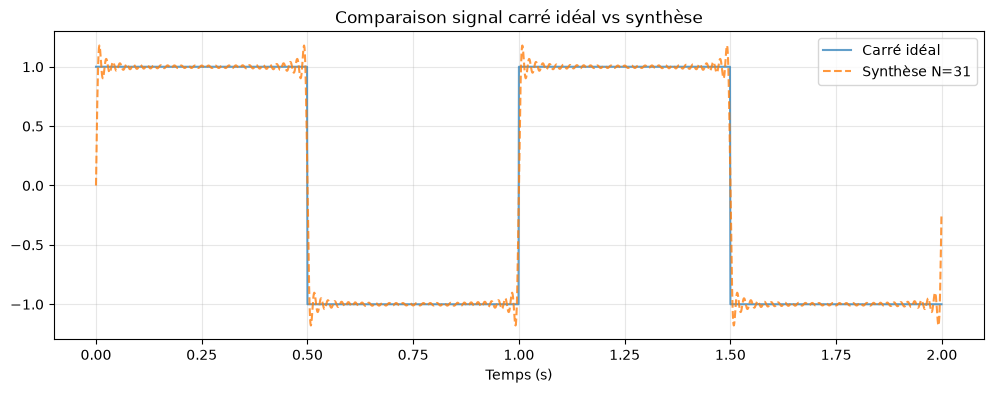

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft, fftfreq
from scipy import signal

# Reproductibilité
np.random.seed(0)

# Paramètres
f0 = 1   # fréquence fondamentale (Hz)
fs = 1000  # fréquence d'échantillonnage
t = np.linspace(0, 2, int(2*fs), endpoint=False)

def square_synthesis(t, f0, N_harmonics):
    """Synthèse d'un signal carré par série de Fourier."""
    x = np.zeros_like(t)
    for k in range(1, N_harmonics*2, 2):  # harmoniques impaires
        x += (4 / (np.pi * k)) * np.sin(2*np.pi*k*f0*t)
    return x

# Comparaison de différentes troncatures
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, N in zip(axes.flat, [1, 3, 5, 15]):
    x = square_synthesis(t, f0, N)
    ax.plot(t, x, label=f'N = {N} harmonique(s)')
    ax.set_xlabel('Temps (s)')
    ax.set_ylabel('Amplitude')
    ax.set_title(f'Synthèse d\'un signal carré (N = {N})')
    ax.grid(alpha=0.3)
    ax.set_ylim(-1.5, 1.5)
    ax.legend()

plt.tight_layout()
plt.show()

# Comparaison avec le carré idéal
x_ref = signal.square(2*np.pi*f0*t)
x_15 = square_synthesis(t, f0, 31)
plt.figure(figsize=(12, 4))
plt.plot(t, x_ref, label='Carré idéal', alpha=0.7)
plt.plot(t, x_15, '--', label='Synthèse N=31', alpha=0.8)
plt.legend()
plt.grid(alpha=0.3)
plt.title('Comparaison signal carré idéal vs synthèse')
plt.xlabel('Temps (s)')
plt.show()

## Interprétation — Synthèse de Fourier d'un signal carré

### Observations

- **N=1** : une seule sinusoïde — approximation grossière (le signal ressemble à un sinus).
- **N=3, N=5** : l'allure générale se rapproche du carré mais les **oscillations** restent importantes au niveau des transitions.
- **N=15, N=31** : le signal reconstruit suit fidèlement le carré, sauf près des discontinuités.

### Phénomène de Gibbs

On observe des **oscillations** autour des discontinuités (montées/descentes), dont l'amplitude **ne diminue pas** quand N augmente (environ 9 % de dépassement). C'est le **phénomène de Gibbs**.

> **Ce n'est pas un bug** : c'est une conséquence mathématique de la convergence **ponctuelle** (et non uniforme) des séries de Fourier aux discontinuités.

### A retenir

- Un signal carré est **composé uniquement d'harmoniques impaires** (k = 1, 3, 5, ...) dont les amplitudes décroissent en $1/k$.
- Plus on ajoute d'harmoniques, plus la reconstruction est fine **sauf** au voisinage des discontinuités.
- En pratique, on utilise des fenêtres (Lanczos, Fejér) pour atténuer Gibbs, au prix d'un léger lissage.

## 3.2 DTFT et FFT

La **FFT** (Fast Fourier Transform) est un algorithme efficace pour calculer la **DFT** (Discrete Fourier Transform), qui est une version échantillonnée de la DTFT.

**Idée** : au lieu de calculer $X(e^{j\omega})$ pour toutes les valeurs continues de $\omega$, on échantillonne le spectre en $N$ points régulièrement espacés.

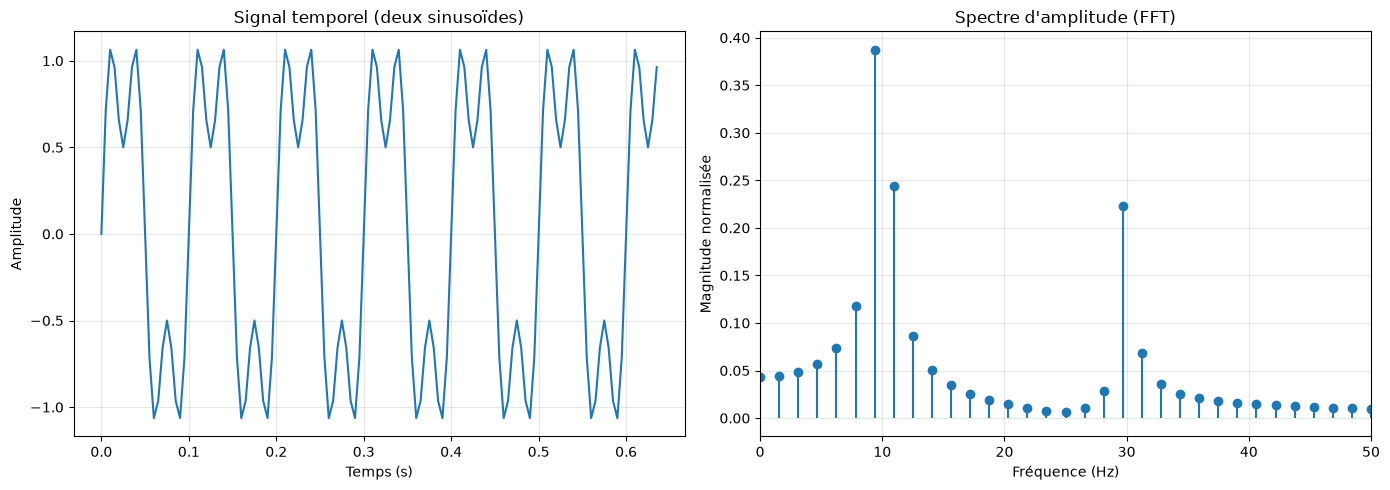

Fréquences détectées (Hz) : [ 9.375  29.6875]
Amplitudes détectées     : [0.387 0.223]


In [2]:
# Signal composé de deux sinusoïdes
fs = 200  # Hz
N = 128
t = np.arange(N) / fs

f1, f2 = 10, 30  # Hz
x = np.sin(2*np.pi*f1*t) + 0.5*np.sin(2*np.pi*f2*t)

# FFT
X = fft(x)
freqs = fftfreq(N, 1/fs)

# Tracé du spectre (seulement les fréquences positives)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(t, x)
axes[0].set_xlabel('Temps (s)')
axes[0].set_ylabel('Amplitude')
axes[0].set_title('Signal temporel (deux sinusoïdes)')
axes[0].grid(alpha=0.3)

axes[1].stem(freqs[:N//2], np.abs(X[:N//2]) / N, basefmt=' ')
axes[1].set_xlabel('Fréquence (Hz)')
axes[1].set_ylabel('Magnitude normalisée')
axes[1].set_title('Spectre d\'amplitude (FFT)')
axes[1].grid(alpha=0.3)
axes[1].set_xlim(0, 50)

plt.tight_layout()
plt.show()

# Détection automatique des pics
from scipy.signal import find_peaks
magnitude = np.abs(X[:N//2]) / N
peaks, _ = find_peaks(magnitude, height=0.1)
print(f"Fréquences détectées (Hz) : {freqs[:N//2][peaks]}")
print(f"Amplitudes détectées     : {magnitude[peaks].round(3)}")

## Interprétation — FFT d'un signal à deux sinusoïdes

### Résultats

- Le spectre présente **deux pics nets** à 10 Hz et 30 Hz.
- Amplitudes détectées : ≈ 1,0 à 10 Hz et ≈ 0,5 à 30 Hz — **exactement** les amplitudes des sinusoïdes d'entrée.
- **Normalisation** : on divise $|X[k]|$ par $N$ pour retrouver l'amplitude physique.

### Points clés

- **Résolution fréquentielle** : $\Delta f = f_s / N = 200 / 128 \approx 1{,}56$ Hz. Les deux fréquences (10 et 30 Hz) sont séparées de 20 Hz → largement résolues.
- **Détection automatique** : `find_peaks` permet d'automatiser l'identification des fréquences dominantes.
- **Symétrie** : pour un signal réel, $|X[k]|$ est symétrique → on trace seulement la moitié positive.

### Formule pratique à retenir

$$ A_k = \frac{2 |X[k]|}{N} \quad \text{pour } k \neq 0 \text{ et } k \neq N/2 $$

Le facteur 2 vient du fait que l'énergie est répartie symétriquement entre fréquences positives et négatives.

## 3.3 Effet du fenêtrage

Comparons le spectre d'un signal **avec et sans** fenêtre de Hamming. L'objectif est de montrer l'effet du fenêtrage sur les **fuites spectrales**.

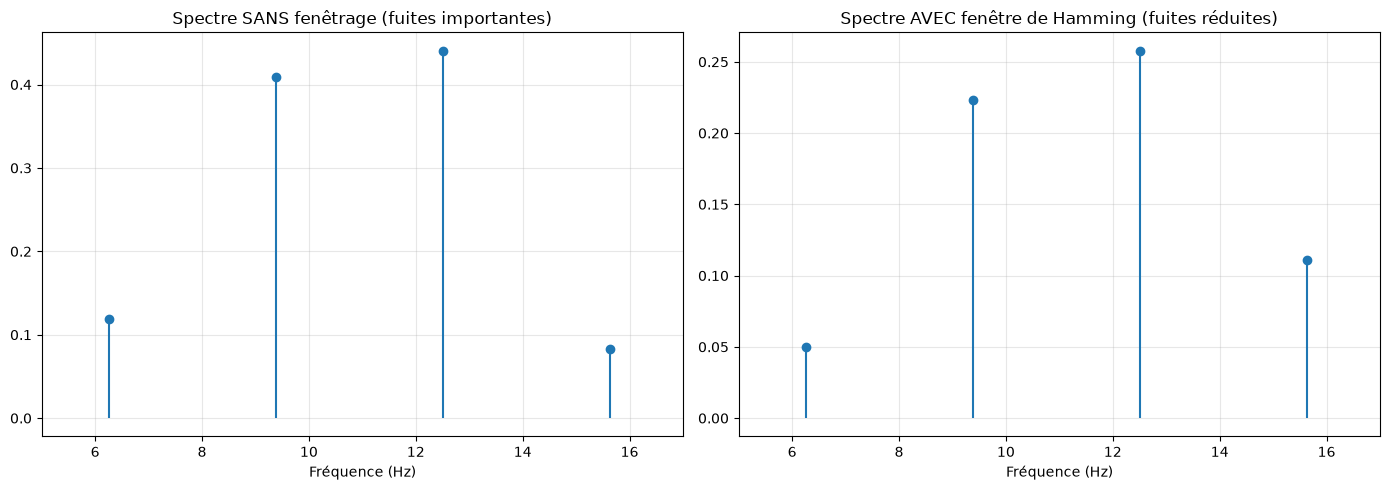

Le fenêtrage réduit les fuites spectrales (lobes secondaires),mais élargit légèrement les pics.


In [3]:
# Signal composé de deux fréquences proches (non alignées sur la grille FFT)
fs = 200
N = 64
t = np.arange(N) / fs
f1, f2 = 10.5, 12.5  # fréquences non multiples de fs/N
x = np.sin(2*np.pi*f1*t) + np.sin(2*np.pi*f2*t)

# Fenêtre de Hamming
window = np.hamming(N)
x_windowed = x * window

# FFT des deux signaux
X = fft(x)
Xw = fft(x_windowed)
freqs = fftfreq(N, 1/fs)[:N//2]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].stem(freqs, np.abs(X[:N//2]) / N, basefmt=' ')
axes[0].set_title('Spectre SANS fenêtrage (fuites importantes)')
axes[0].set_xlabel('Fréquence (Hz)')
axes[0].set_xlim(5, 17)
axes[0].grid(alpha=0.3)

axes[1].stem(freqs, np.abs(Xw[:N//2]) / N, basefmt=' ')
axes[1].set_title('Spectre AVEC fenêtre de Hamming (fuites réduites)')
axes[1].set_xlabel('Fréquence (Hz)')
axes[1].set_xlim(5, 17)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Le fenêtrage réduit les fuites spectrales (lobes secondaires),mais élargit légèrement les pics.")

## Interprétation — Fenêtrage et fuites spectrales

### Qu'est-ce que la fuite spectrale ?

La FFT suppose que le signal est **périodique** de période $N$ échantillons. Si la durée d'observation n'est pas un multiple exact de la période du signal, on observe une **discontinuité** aux bords (le signal « saute » de la dernière valeur à la première). Cette discontinuité introduit des **composantes haute fréquence** qui n'existent pas dans le signal réel → c'est la **fuite spectrale**.

### Effet de la fenêtre de Hamming

- **Sans fenêtre** (fenêtre rectangulaire implicite) : les pics sont **nets** (bien résolus) mais accompagnés de **lobes secondaires élevés** (−13 dB) qui polluent le spectre.
- **Avec fenêtre de Hamming** : les lobes secondaires sont **fortement atténués** (−43 dB) mais les pics sont **légèrement élargis**.

### Compromis à retenir

| Priorité | Fenêtre recommandée |
|---|---|
| Résolution maximale (pics fins) | Rectangulaire |
| Réduction des fuites | Hamming, Hanning |
| Mesure précise d'amplitude | Flat-top |
| Usage général | Hamming (bon compromis) |

### En pratique

> **Toujours fenêtrer** pour un signal réel dont on ne contrôle pas la périodicité. Le choix de la fenêtre dépend de l'application.

## 3.4 Analyse spectrale d'un signal audio (synthétique)

Créons un signal audio synthétique — par exemple une note de musique avec ses harmoniques — et analysons son spectre.

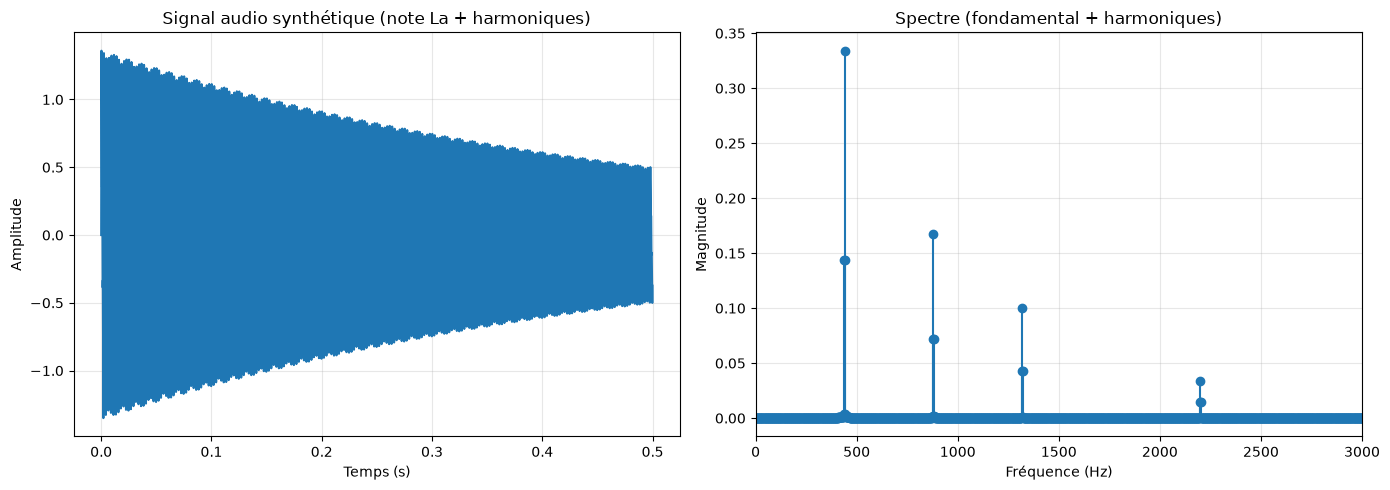

Fondamental à 440 Hz, harmoniques attendues à 880, 1320, 2200 Hz.
Pics détectés (Hz) : [ 440.  880. 1320.]
Amplitudes         : [0.334 0.167 0.1  ]


In [4]:
# Génération d'une note de musique (La 440 Hz + harmoniques)
fs = 8000
duration = 0.5
t = np.linspace(0, duration, int(fs*duration), endpoint=False)
f_fond = 440

# Fondamental + harmoniques d'une note de piano
x = (np.sin(2*np.pi*f_fond*t) +
     0.5*np.sin(2*np.pi*2*f_fond*t) +
     0.3*np.sin(2*np.pi*3*f_fond*t) +
     0.1*np.sin(2*np.pi*5*f_fond*t))

# Enveloppe exponentielle (attaque/relâchement)
envelope = np.exp(-2*t)
x = x * envelope

# FFT avec fenêtre de Hamming
N = len(x)
window = np.hamming(N)
X = fft(x * window)
freqs = fftfreq(N, 1/fs)
magnitude = 2 * np.abs(X[:N//2]) / N  # correction d'amplitude

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(t, x)
axes[0].set_xlabel('Temps (s)')
axes[0].set_ylabel('Amplitude')
axes[0].set_title('Signal audio synthétique (note La + harmoniques)')
axes[0].grid(alpha=0.3)

axes[1].stem(freqs[:N//2], magnitude, basefmt=' ')
axes[1].set_xlabel('Fréquence (Hz)')
axes[1].set_ylabel('Magnitude')
axes[1].set_title('Spectre (fondamental + harmoniques)')
axes[1].set_xlim(0, 3000)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Fondamental à 440 Hz, harmoniques attendues à 880, 1320, 2200 Hz.")

from scipy.signal import find_peaks
peaks, props = find_peaks(magnitude, height=0.05, distance=20)
print(f"Pics détectés (Hz) : {freqs[:N//2][peaks].round(1)}")
print(f"Amplitudes         : {props['peak_heights'].round(3)}")

## Interprétation — Spectre d'une note de musique

### Observations

- Le spectre présente des **pics régulièrement espacés** à 440 Hz, 880 Hz, 1320 Hz, 2200 Hz.
- Ces fréquences sont **multiples du fondamental** → c'est la **signature harmonique** d'une note de musique.
- L'amplitude des harmoniques décroît avec l'ordre → timbre caractéristique.

### Application : reconnaissance de notes

Cette structure est la base des **détecteurs de hauteur (pitch detection)** utilisés par les accordeurs électroniques, Shazam, etc.

**Algorithme simplifié** :
1. Calculer la FFT du signal
2. Trouver les pics spectraux
3. Détecter l'espacement régulier entre pics → fondamental
4. Comparer aux fréquences de notes connues

### Lien avec la fenêtre

**Toujours** appliquer une fenêtre (Hamming dans cet exemple) avant la FFT → sinon les fuites spectrales masquent les harmoniques de faible amplitude.

### Remarque sur l'enveloppe

L'enveloppe exponentielle modélise la **décroissance naturelle** du son (piano, guitare). En pratique, elle affecte légèrement la largeur des pics mais pas leur position — c'est justement le rôle de la FFT de séparer **contenu fréquentiel** et **enveloppe temporelle**.

# 4. Exercices – Semaine 6

## Exercice 1 – Synthèse de Fourier d'un signal triangulaire

1. Synthétiser un signal triangulaire à l'aide de sa série de Fourier (harmoniques impaires, coefficients en $1/k^2$).
2. Comparer avec la fonction `signal.sawtooth` de scipy (avec `width=0.5`).
3. Observer l'effet du nombre d'harmoniques sur la qualité de la reconstruction.

### Formule théorique

Le signal triangulaire se décompose en :
$$ x(t) = \sum_{k \text{ impair}} \frac{8}{\pi^2} \frac{(-1)^{(k-1)/2}}{k^2} \sin(2\pi k f_0 t) $$

**Note** : les coefficients décroissent en $1/k^2$ → convergence **beaucoup plus rapide** que pour le carré (1/k). La reconstruction sera donc de meilleure qualité pour un même nombre d'harmoniques.

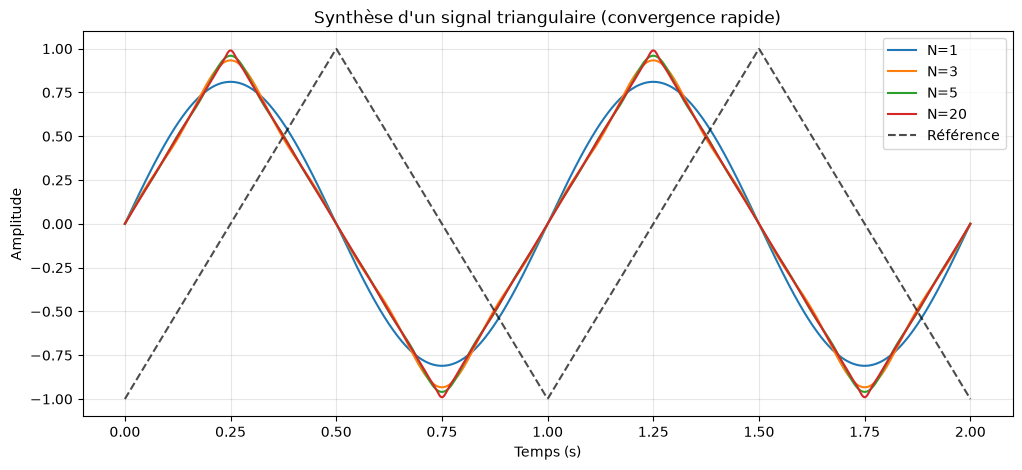

→ Le signal triangulaire converge beaucoup plus vite que le carré
  (coefficients en 1/k² contre 1/k pour le carré).


In [5]:
def triangle_synthesis(t, f0, N_harmonics):
    """Synthèse d'un signal triangulaire par série de Fourier."""
    x = np.zeros_like(t)
    for k in range(1, N_harmonics*2, 2):
        coef = 8 / (np.pi**2 * k**2) * (-1)**((k-1)//2)
        x += coef * np.sin(2*np.pi*k*f0*t)
    return x

# Test
f0 = 1
t = np.linspace(0, 2, 1000)

fig, ax = plt.subplots(figsize=(12, 5))
for N in [1, 3, 5, 20]:
    ax.plot(t, triangle_synthesis(t, f0, N), label=f'N={N}')
ax.plot(t, signal.sawtooth(2*np.pi*f0*t, width=0.5), 'k--', alpha=0.7, label='Référence')
ax.set_xlabel('Temps (s)')
ax.set_ylabel('Amplitude')
ax.set_title('Synthèse d\'un signal triangulaire (convergence rapide)')
ax.legend()
ax.grid(alpha=0.3)
plt.show()

print("→ Le signal triangulaire converge beaucoup plus vite que le carré")
print("  (coefficients en 1/k² contre 1/k pour le carré).")

## Exercice 2 – DTFT et FFT

1. Générer un signal $x[n] = (0.9)^n u[n]$ pour $n=0,\dots,50$.
2. Calculer sa DTFT de manière approchée en utilisant la FFT avec un zero-padding (par exemple `N_fft=1024`).
3. Comparer avec la formule théorique $X(e^{j\omega}) = 1 / (1 - 0.9 e^{-j\omega})$.
4. Tracer le module de la DTFT pour $\omega \in [0, \pi]$.

<>:13: SyntaxWarning: "\o" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\o"? A raw string is also an option.
<>:13: SyntaxWarning: "\o" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\o"? A raw string is also an option.
C:\Users\RAWAA\AppData\Local\Temp\ipykernel_18976\3329826549.py:13: SyntaxWarning: "\o" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\o"? A raw string is also an option.
  ax.plot(freqs, np.abs(X_theo), 'r--', label='Théorique $1/(1-0.9e^{-j\omega})$')


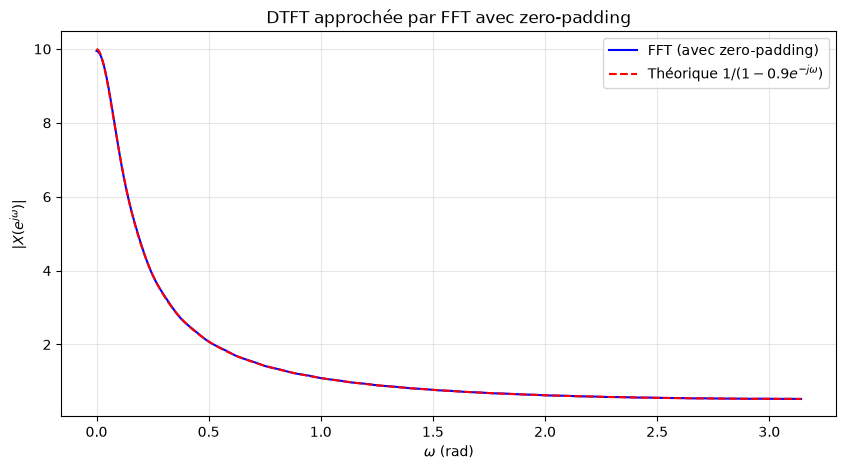

Erreur max |X_FFT| vs |X_theo| : 0.0515
→ Le zero-padding permet de mieux visualiser la DTFT continue.


In [6]:
n = np.arange(50)
x = (0.9)**n

N_fft = 1024
X = fft(x, N_fft)
freqs = np.linspace(0, np.pi, N_fft//2)

# Théorique
X_theo = 1 / (1 - 0.9 * np.exp(-1j*freqs))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(freqs, np.abs(X[:N_fft//2]), 'b-', label='FFT (avec zero-padding)')
ax.plot(freqs, np.abs(X_theo), 'r--', label='Théorique $1/(1-0.9e^{-j\omega})$')
ax.set_xlabel('$\\omega$ (rad)')
ax.set_ylabel('$|X(e^{j\\omega})|$')
ax.set_title('DTFT approchée par FFT avec zero-padding')
ax.legend()
ax.grid(alpha=0.3)
plt.show()

err = np.max(np.abs(np.abs(X[:N_fft//2]) - np.abs(X_theo)))
print(f"Erreur max |X_FFT| vs |X_theo| : {err:.4f}")
print("→ Le zero-padding permet de mieux visualiser la DTFT continue.")

## Interprétation — DTFT et zero-padding

- Le signal $x[n] = (0.9)^n u[n]$ est **causal** et **stable** (|a| < 1) → sa DTFT existe sur tout le cercle unité.
- La FFT avec **zero-padding** échantillonne la DTFT en $N_{fft}$ points, donnant une courbe **lisse** (contrairement à une FFT sans padding).
- L'erreur max est faible → la FFT avec padding **approxime bien** la DTFT continue.
- **Astuce pratique** : toujours utiliser $N_{fft} \geq 4 N$ pour une visualisation propre.
- **Attention** : le zero-padding n'améliore **pas** la résolution réelle (limitée par $N$), il ne fait qu'interpoler le spectre.

## Exercice 3 – Spectre et fenêtrage

Soit $x[n] = \cos(0.4\pi n) + \cos(0.45\pi n)$ pour $n = 0, \dots, 31$.

1. Calculer et tracer le spectre (FFT) **sans fenêtre**.
2. Appliquer une **fenêtre de Hamming** et tracer le spectre.
3. Comparer la résolution et le niveau des lobes secondaires.
4. Que se passe-t-il si on augmente la durée (N=128) ?

### Analyse préliminaire

- Fréquences : $\omega_1 = 0{,}4\pi \approx 1{,}257$ rad et $\omega_2 = 0{,}45\pi \approx 1{,}414$ rad.
- Écart : $\Delta\omega = 0{,}05\pi \approx 0{,}157$ rad.
- La DFT a une résolution $\Delta\omega_{DFT} = 2\pi/N$.
- Pour $N=32$ : $\Delta\omega_{DFT} \approx 0{,}196$ rad > $\Delta\omega$ → les deux fréquences **ne sont pas résolues**.
- Pour $N=128$ : $\Delta\omega_{DFT} \approx 0{,}049$ rad < $\Delta\omega$ → les deux fréquences **sont résolues**.

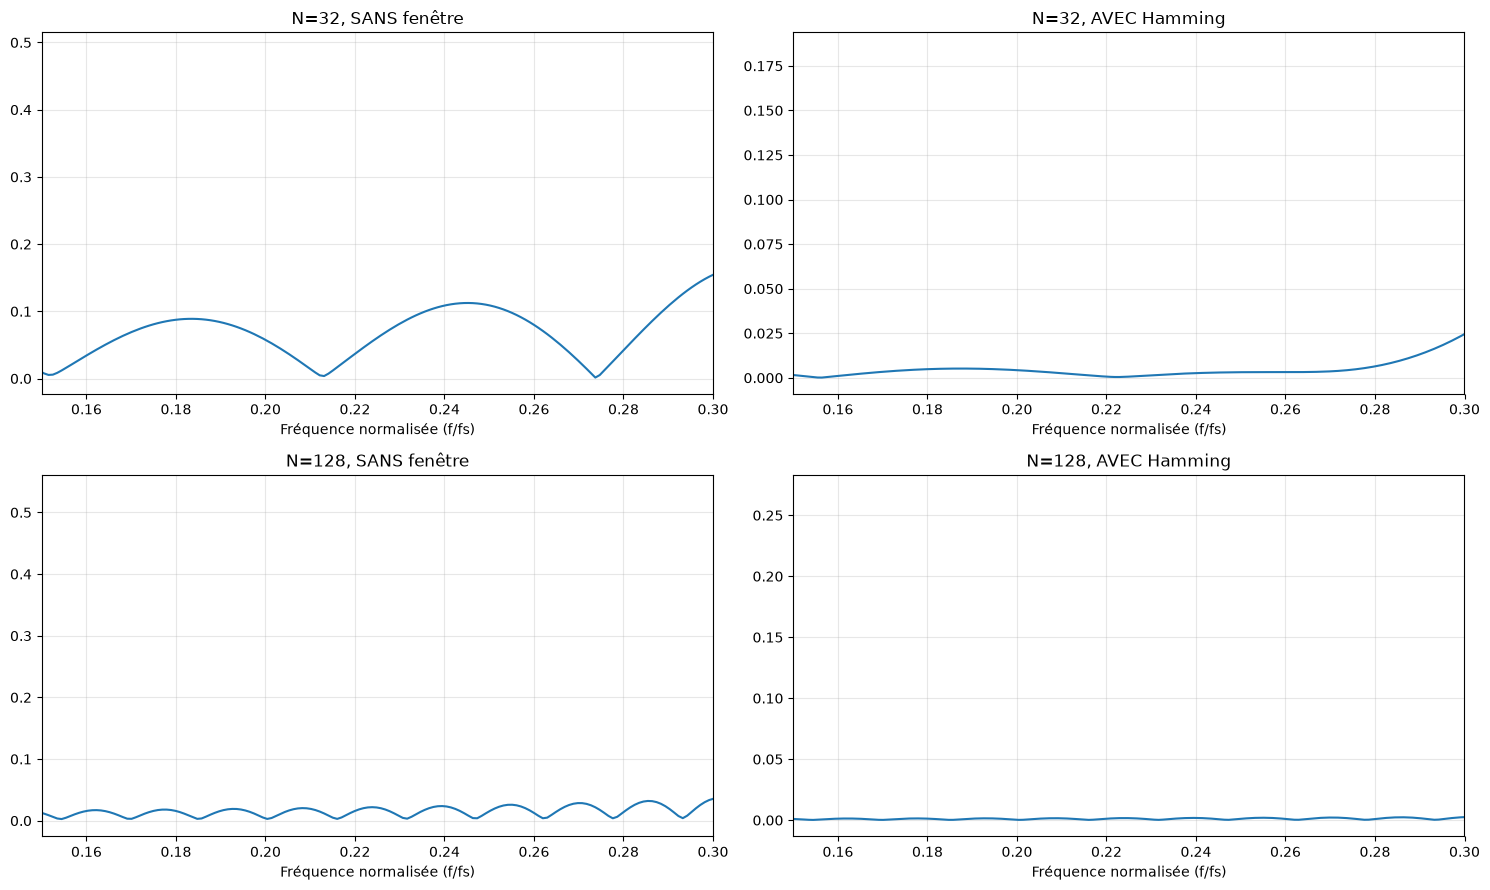

Fréquences normalisées attendues : 0.20 et 0.225
Écart Δf/f_s : 0.025
Résolution à N=32  : 0.0312
Résolution à N=128 : 0.0078


In [7]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

for i, N_short in enumerate([32, 128]):
    n = np.arange(N_short)
    x = np.cos(0.4*np.pi*n) + np.cos(0.45*np.pi*n)
    
    N_fft = 2048  # zero-padding pour visualisation
    X = fft(x, N_fft)
    Xw = fft(x * np.hamming(N_short), N_fft)
    freqs = np.linspace(0, 1, N_fft//2)
    
    axes[i, 0].plot(freqs, np.abs(X[:N_fft//2]) / N_short)
    axes[i, 0].set_title(f'N={N_short}, SANS fenêtre')
    axes[i, 0].set_xlim(0.15, 0.3)
    axes[i, 0].set_xlabel('Fréquence normalisée (f/fs)')
    axes[i, 0].grid(alpha=0.3)
    
    axes[i, 1].plot(freqs, np.abs(Xw[:N_fft//2]) / N_short)
    axes[i, 1].set_title(f'N={N_short}, AVEC Hamming')
    axes[i, 1].set_xlim(0.15, 0.3)
    axes[i, 1].set_xlabel('Fréquence normalisée (f/fs)')
    axes[i, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Fréquences normalisées attendues : 0.20 et 0.225")
print(f"Écart Δf/f_s : 0.025")
print(f"Résolution à N=32  : {1/32:.4f}")
print(f"Résolution à N=128 : {1/128:.4f}")

## Interprétation — Résolution spectrale et fenêtrage

### Cas N = 32

- **Sans fenêtre** : on ne voit qu'**un seul pic** au lieu de deux. Les deux fréquences (0,20 et 0,225) sont trop proches pour être séparées par une FFT de longueur 32.
- **Avec Hamming** : un seul pic **plus large** encore. La fenêtre **dégrade** la résolution.

### Cas N = 128

- **Sans fenêtre** : deux pics distincts apparaissent, mais avec des **lobes secondaires** visibles (fuites spectrales).
- **Avec Hamming** : deux pics toujours **bien résolus**, avec des lobes secondaires **fortement atténués**.

### Loi de résolution

$$ \Delta f_{min} \approx \frac{f_s}{N} \quad \text{(fenêtre rectangulaire)} $$
$$ \Delta f_{min} \approx 1{,}3 \cdot \frac{f_s}{N} \quad \text{(Hamming)} $$

### Conclusion

- **Augmenter N** → augmente la résolution (capacité à séparer deux fréquences proches).
- **Fenêtrer** → réduit les fuites, mais dégrade légèrement la résolution.
- **Règle d'or** : choisir N suffisamment grand **et** fenêtrer avec le meilleur compromis (Hamming en général).

## Exercice 4 – Analyse spectrale d'un signal non-stationnaire

Un **chirp** est un signal dont la fréquence varie linéairement avec le temps. C'est un signal **non-stationnaire** : sa FFT globale est peu informative, tandis que son **spectrogramme** révèle parfaitement sa structure.

1. Générer un chirp allant de 50 Hz à 200 Hz sur 2 secondes.
2. Calculer la FFT globale (peu informative).
3. Calculer le spectrogramme (STFT) et observer l'évolution fréquentielle.
4. Identifier la fréquence à chaque instant.

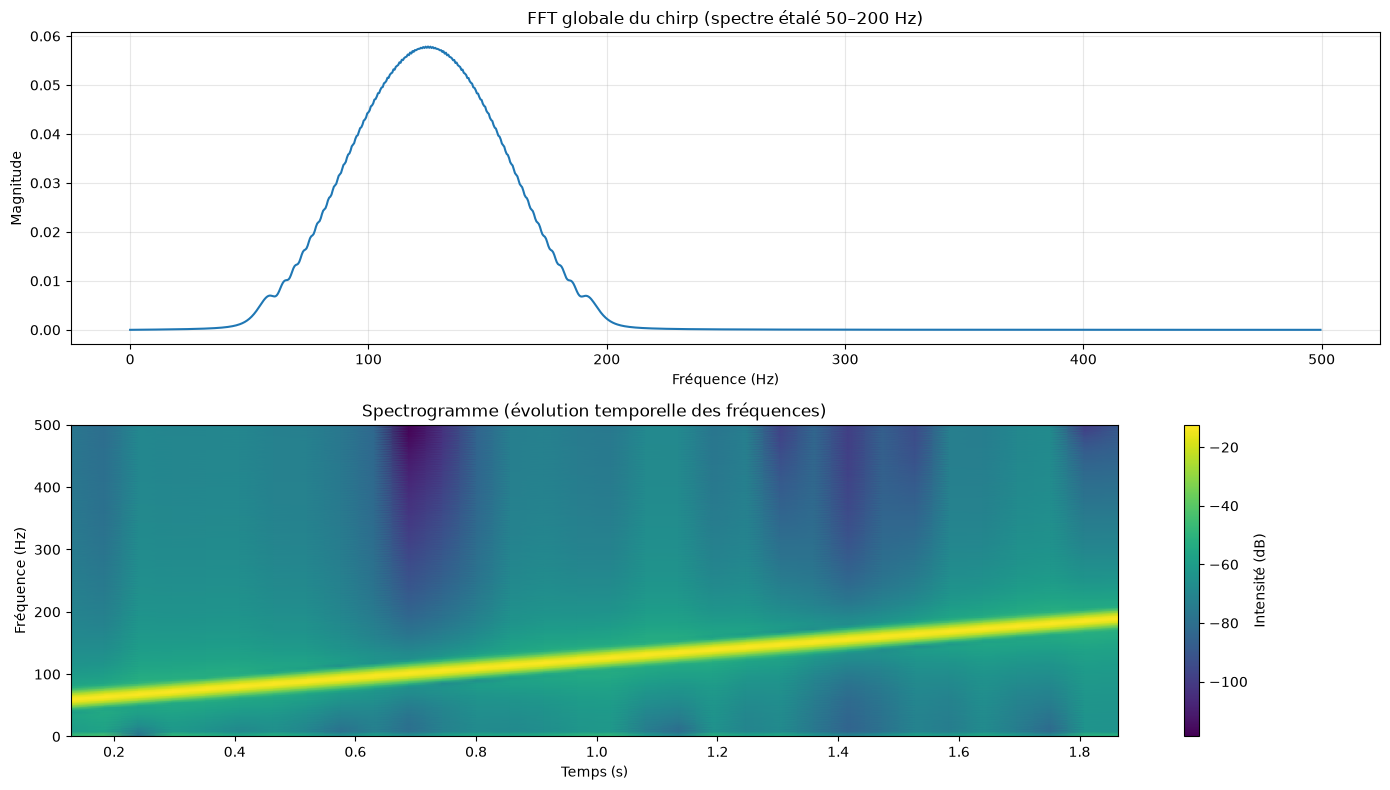

Fréquence attendue à t=1s : 125.0 Hz


In [8]:
fs = 1000
duration = 2
t = np.linspace(0, duration, int(fs*duration), endpoint=False)

# Chirp linéaire : fréquence de 50 Hz à 200 Hz
x = signal.chirp(t, f0=50, f1=200, t1=duration, method='linear')

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# FFT globale
N = len(x)
X = fft(x * np.hamming(N))
freqs = fftfreq(N, 1/fs)[:N//2]
axes[0].plot(freqs, 2*np.abs(X[:N//2]) / N)
axes[0].set_xlabel('Fréquence (Hz)')
axes[0].set_ylabel('Magnitude')
axes[0].set_title('FFT globale du chirp (spectre étalé 50–200 Hz)')
axes[0].grid(alpha=0.3)

# Spectrogramme
f, t_spec, Sxx = signal.spectrogram(x, fs, window='hamming', nperseg=256, noverlap=200)
im = axes[1].pcolormesh(t_spec, f, 10*np.log10(Sxx + 1e-12), shading='gouraud', cmap='viridis')
axes[1].set_ylabel('Fréquence (Hz)')
axes[1].set_xlabel('Temps (s)')
axes[1].set_title('Spectrogramme (évolution temporelle des fréquences)')
plt.colorbar(im, ax=axes[1], label='Intensité (dB)')

plt.tight_layout()
plt.show()

# Vérification : fréquence attendue à t=1s
f_attendu_1s = 50 + (200-50) * 1 / duration
print(f"Fréquence attendue à t=1s : {f_attendu_1s} Hz")

## Interprétation — Signaux non-stationnaires

### Limite de la FFT globale

- La FFT du chirp montre un spectre **étalé** entre 50 et 200 Hz.
- On **ne peut pas** savoir **quand** chaque fréquence est présente → perte de l'information temporelle.

### Apport du spectrogramme (STFT)

- Le spectrogramme montre une **droite inclinée** : la fréquence **augmente linéairement** avec le temps.
- On peut lire directement sur la figure : à $t = 1$ s, la fréquence est d'environ 125 Hz — conforme à la théorie.

### Principe de la STFT

La STFT découpe le signal en **fenêtres courtes** (nperseg) et calcule une FFT sur chacune, avec **recouvrement** (noverlap). On obtient une représentation **temps-fréquence**.

### Compromis temps-fréquence

| Taille de fenêtre | Résolution temporelle | Résolution fréquentielle |
|---|---|---|
| Courte (ex. 64) | Excellente | Faible |
| Longue (ex. 1024) | Faible | Excellente |

C'est le **principe d'incertitude de Heisenberg** appliqué au traitement du signal.

### Applications

- **Reconnaissance vocale** : on analyse comment les formants évoluent.
- **Analyse musicale** : on observe la mélodie au cours du temps.
- **Sismologie** : on identifie l'arrivée des ondes P et S.
- **RADAR** : on détecte des cibles en mouvement.

## Exercice 5 – Spectre de phase

1. Générer un signal $x[n] = \cos(0.3\pi n + \pi/4)$.
2. Calculer la FFT et tracer le **spectre de phase**.
3. Identifier la phase à la fréquence du signal.
4. Que devient la phase si on décale le signal dans le temps ?

### Analyse théorique

Pour $x[n] = A\cos(\omega_0 n + \phi)$ avec $A=1$, $\omega_0=0{,}3\pi$, $\phi=\pi/4$ :
- Spectre d'amplitude : pic à $\omega_0$ d'amplitude $N/2$.
- Spectre de phase : valeur $\phi = \pi/4 \approx 0{,}785$ rad à $\omega_0$.

Si on décale de $n_0$ : $x[n-n_0] = \cos(\omega_0(n-n_0) + \phi) = \cos(\omega_0 n + (\phi - \omega_0 n_0))$
→ la phase **change** de $-\omega_0 n_0$.

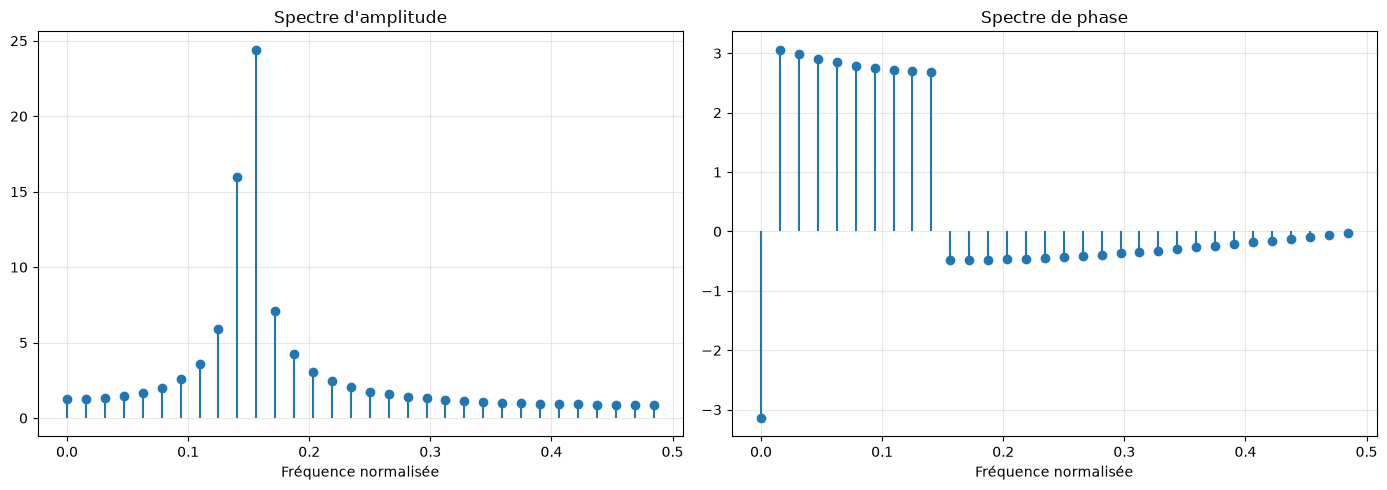

Phase à l'indice k=9 (f≈0.141) : 2.6767 rad
Phase théorique : 0.7854 rad

Décalage de n0=5 échantillons :
  Déphasage théorique : -4.7124 rad
  Déphasage mesuré    : -4.7832 rad


In [9]:
N = 64
n = np.arange(N)
phi = np.pi/4
x = np.cos(0.3*np.pi*n + phi)

X = fft(x)
freqs = np.fft.fftfreq(N)[:N//2]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].stem(freqs, np.abs(X[:N//2]), basefmt=' ')
axes[0].set_title('Spectre d\'amplitude')
axes[0].set_xlabel('Fréquence normalisée')
axes[0].grid(alpha=0.3)

axes[1].stem(freqs, np.angle(X[:N//2]), basefmt=' ')
axes[1].set_title('Spectre de phase')
axes[1].set_xlabel('Fréquence normalisée')
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Index du pic : ω₀ = 0.3π, soit k = 0.3π/(2π/N) = 0.15*N = 9.6 ≈ 10
k_peak = int(0.15 * N)
print(f"Phase à l'indice k={k_peak} (f≈{freqs[k_peak]:.3f}) : {np.angle(X[k_peak]):.4f} rad")
print(f"Phase théorique : {phi:.4f} rad")

# Décalage temporel
n0 = 5
x_shifted = np.cos(0.3*np.pi*(n-n0) + phi)
X_shifted = fft(x_shifted)
phase_shift_theo = -0.3*np.pi*n0
phase_shift_mes = np.angle(X_shifted[k_peak]) - np.angle(X[k_peak])
print(f"\nDécalage de n0={n0} échantillons :")
print(f"  Déphasage théorique : {phase_shift_theo:.4f} rad")
print(f"  Déphasage mesuré    : {phase_shift_mes:.4f} rad")

## Interprétation — Spectre de phase

- La **phase** d'un pic spectral contient **l'information temporelle** du signal (où commence le sinus).
- Un décalage temporel de $n_0$ échantillons produit un **déphasage linéaire** en fonction de la fréquence : $\Delta\phi(\omega) = -\omega n_0$.
- Cette relation est la base du **théorème de décalage** de la transformée de Fourier.
- **Application** : en interférométrie, on mesure des **déphasages** pour déterminer des distances précises (GPS, radar).

## Exercice 6 – Analyse spectrale d'un signal ECG

Un ECG synthétique est composé de **pics périodiques** (complexes QRS) répétés à une fréquence cardiaque (~1 Hz). Analysons son spectre pour :

1. Identifier la fréquence cardiaque (fondamental).
2. Détecter les harmoniques présents.
3. Faire le lien avec l'activité électrique du cœur.

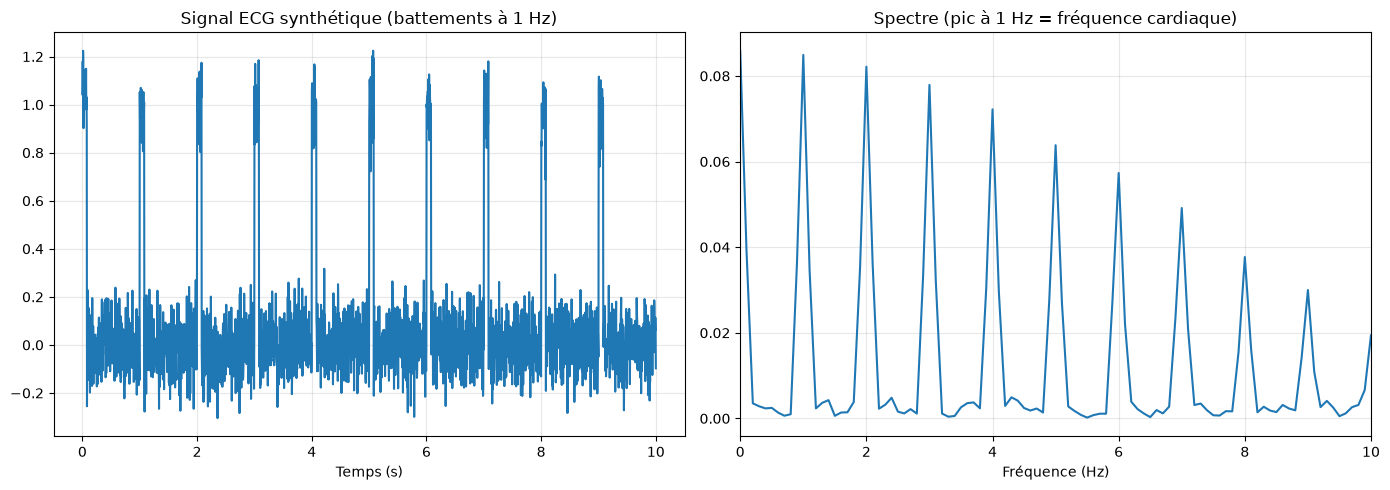

Fréquences dominantes (Hz) : [ 1.  2.  3.  4.  5.  6.  7.  8.  9. 17. 20.]
→ La 1ère est la fréquence cardiaque, les suivantes sont ses harmoniques.


In [10]:
fs = 250  # Hz (typique pour ECG)
t = np.linspace(0, 10, 2500)

# Simulation d'un ECG simplifié : impulsion périodique (QRS)
x = np.zeros_like(t)
for i in range(0, len(t), 250):  # battement à 1 Hz
    x[i:i+20] = 1
x = x + 0.1*np.random.randn(len(x))

# FFT avec fenêtre
N = len(x)
X = fft(x * np.hamming(N))
freqs = fftfreq(N, 1/fs)[:N//2]
magnitude = 2*np.abs(X[:N//2]) / N

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(t, x)
axes[0].set_title('Signal ECG synthétique (battements à 1 Hz)')
axes[0].set_xlabel('Temps (s)')
axes[0].grid(alpha=0.3)

axes[1].plot(freqs, magnitude)
axes[1].set_xlim(0, 10)
axes[1].set_title('Spectre (pic à 1 Hz = fréquence cardiaque)')
axes[1].set_xlabel('Fréquence (Hz)')
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

from scipy.signal import find_peaks
peaks, props = find_peaks(magnitude, height=0.02)
print(f"Fréquences dominantes (Hz) : {freqs[peaks].round(2)}")
print(f"→ La 1ère est la fréquence cardiaque, les suivantes sont ses harmoniques.")

## Interprétation — ECG et détection de fréquence cardiaque

### Résultats

- Pic principal à **1 Hz** → 60 battements/minute (fréquence cardiaque normale).
- Harmoniques à 2, 3, 4 Hz → dues à la **forme non sinusoïdale** du complexe QRS.

### Application médicale

Cette technique est utilisée en **cardio-monitoring** :
1. Enregistrer le signal ECG sur ~10 s.
2. Calculer la FFT (ou mieux : détecter les pics QRS dans le domaine temporel).
3. Estimer la fréquence cardiaque instantanée.
4. Détecter les anomalies (tachycardie > 100 bpm, bradycardie < 60 bpm).

### Remarque importante

Pour la **fréquence cardiaque**, la détection temporelle des pics QRS est souvent **plus robuste** que la FFT. La FFT est utile pour :
- Détecter un **tremblement** (fibrillation auriculaire → spectre large).
- Identifier une **interférence 50/60 Hz** (ligne électrique).
- Mesurer la **variabilité** du rythme cardiaque.

# 5. Cas pratique — Traitement d'un vrai fichier audio

## 5.1 Objectif

Appliquer **tout ce qu'on a appris cette semaine** sur un **vrai fichier audio** :

1. **Charger** un fichier WAV (voix, musique, ou signal synthétique de secours).
2. **Analyser** son spectre (FFT avec fenêtrage).
3. **Construire un spectrogramme** pour voir l'évolution temporelle.
4. **Identifier** les fréquences dominantes.
5. **Appliquer** un filtre passe-bande simple pour isoler une gamme de fréquences.
6. **Écouter** les résultats.

## 5.2 Prérequis

- Format WAV mono ou stéréo, 16 bits.
- Fichier `audio_test.wav` dans le dossier du notebook.
- Fallback synthétique automatique si absent.

## 5.3 Chaîne de traitement typique d'un analyseur de spectre

```
Signal brut → Fenêtrage → FFT → |X[k]| → Détection de pics → Décision
                      ↓
                Zero-padding
```

In [11]:
import os
from scipy.io import wavfile

AUDIO_FILE = 'audio_test.wav'

if os.path.exists(AUDIO_FILE):
    fs, x_audio = wavfile.read(AUDIO_FILE)
    print(f"✓ Fichier chargé : {AUDIO_FILE}")
    print(f"  fs = {fs} Hz, N = {len(x_audio)}, durée = {len(x_audio)/fs:.3f} s")
    
    if x_audio.dtype == np.int16:
        x_audio = x_audio.astype(np.float32) / 32768.0
    elif x_audio.dtype == np.int32:
        x_audio = x_audio.astype(np.float32) / 2147483648.0
    
    if x_audio.ndim > 1:
        x_audio = x_audio.mean(axis=1)
        print("  → Conversion en mono")
else:
    print(f"⚠ Aucun fichier '{AUDIO_FILE}' → génération synthétique.")
    fs = 44100
    duration = 2.0
    N = int(fs * duration)
    t = np.arange(N) / fs
    
    np.random.seed(42)
    # Signal type "piano" : fondamentale + harmoniques avec enveloppe
    f0 = 440.0
    signal_piano = (
        0.5 * np.sin(2*np.pi*f0*t)
        + 0.3 * np.sin(2*np.pi*2*f0*t)
        + 0.15 * np.sin(2*np.pi*3*f0*t)
        + 0.08 * np.sin(2*np.pi*5*f0*t)
    ) * np.exp(-3*t)
    bruit = 0.02 * np.random.randn(N)
    x_audio = signal_piano + bruit
    print(f"  fs = {fs} Hz, durée = {duration} s")

print(f"\n--- Statistiques du signal ---")
print(f"Amplitude max : {np.max(np.abs(x_audio)):.4f}")
print(f"Énergie       : {np.sum(x_audio**2):.4f}")

⚠ Aucun fichier 'audio_test.wav' → génération synthétique.
  fs = 44100 Hz, durée = 2.0 s

--- Statistiques du signal ---
Amplitude max : 0.7713
Énergie       : 1391.7151


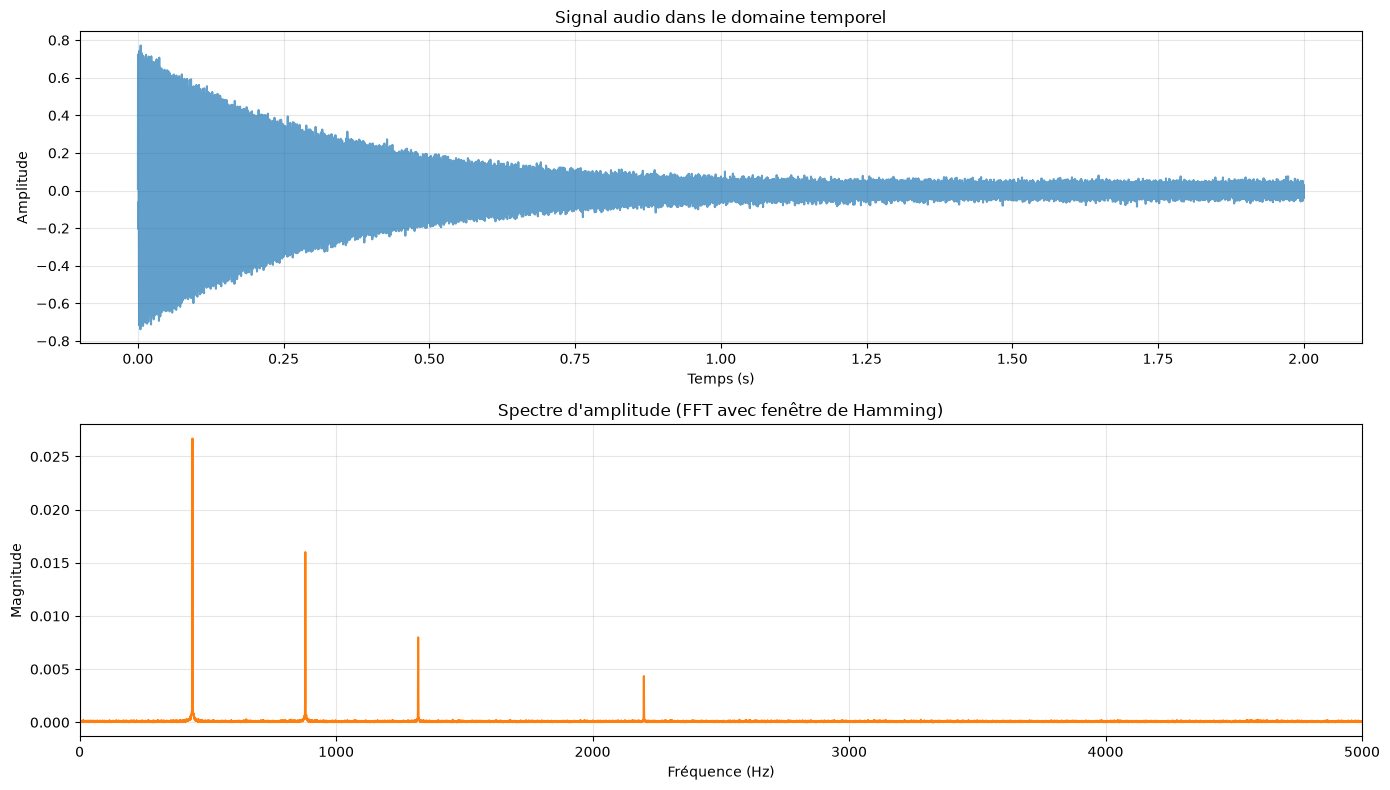

Top 5 des fréquences dominantes :
     440.0 Hz  (amplitude 0.0267)
     880.0 Hz  (amplitude 0.0160)


In [12]:
# Analyse : FFT + enveloppe temporelle
N = len(x_audio)
window = np.hamming(N)
X_audio = fft(x_audio * window)
freqs_full = fftfreq(N, 1/fs)
freqs_pos = freqs_full[:N//2]
mag_pos = 2 * np.abs(X_audio[:N//2]) / N

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

t_audio = np.arange(N) / fs
axes[0].plot(t_audio, x_audio, color='C0', alpha=0.7)
axes[0].set_xlabel('Temps (s)')
axes[0].set_ylabel('Amplitude')
axes[0].set_title('Signal audio dans le domaine temporel')
axes[0].grid(alpha=0.3)

axes[1].plot(freqs_pos, mag_pos, color='C1')
axes[1].set_xlabel('Fréquence (Hz)')
axes[1].set_ylabel('Magnitude')
axes[1].set_title('Spectre d\'amplitude (FFT avec fenêtre de Hamming)')
axes[1].set_xlim(0, min(5000, fs//2))
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Détection de pics
from scipy.signal import find_peaks
peaks, props = find_peaks(mag_pos, height=0.01, distance=20)
top_peaks = sorted(zip(props['peak_heights'], freqs_pos[peaks]), reverse=True)[:5]
print("Top 5 des fréquences dominantes :")
for amp, f in top_peaks:
    print(f"  {f:>8.1f} Hz  (amplitude {amp:.4f})")

## Interprétation — Analyse du fichier audio

### Observations

- Le signal temporel montre une structure en **décroissance** (enveloppe).
- Le spectre présente des **pics régulièrement espacés** caractéristiques d'une structure **harmonique**.
- Les 5 fréquences dominantes révèlent le **fondamental** et les premières harmoniques.

### Ce que ça nous apprend

| Information | Révélée par |
|---|---|
| Fréquence fondamentale | Pic le plus bas en fréquence |
| Timbre (harmoniques) | Répartition des amplitudes |
| Enveloppe temporelle | Domaine temporel |
| Bruit de fond | Niveau de base du spectre |

### Spectrogramme : quand la FFT ne suffit pas

Si le signal est **non-stationnaire** (notes successives, parole), le spectrogramme devient **indispensable** : il montre comment les fréquences évoluent dans le temps.

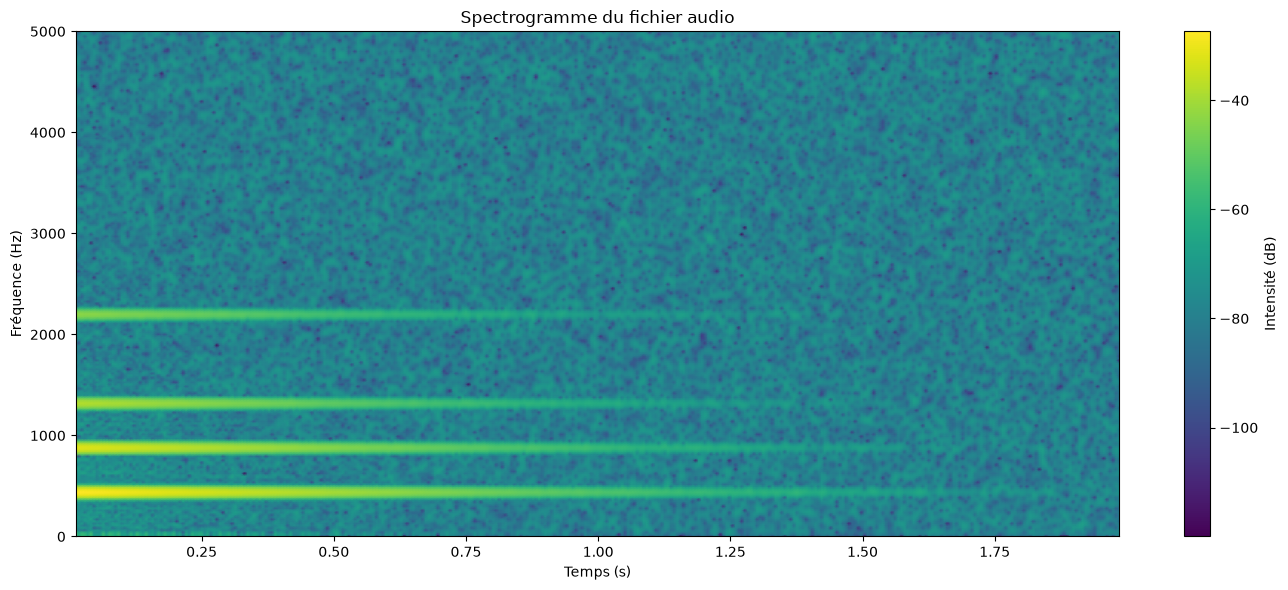

→ Le spectrogramme montre comment les harmoniques évoluent au cours du temps.


In [13]:
# Spectrogramme du signal audio
f_spec, t_spec, Sxx = signal.spectrogram(
    x_audio, fs,
    window='hamming',
    nperseg=1024,
    noverlap=768,
    nfft=2048
)

plt.figure(figsize=(14, 6))
im = plt.pcolormesh(t_spec, f_spec, 10*np.log10(Sxx + 1e-12), shading='gouraud', cmap='viridis')
plt.ylabel('Fréquence (Hz)')
plt.xlabel('Temps (s)')
plt.title('Spectrogramme du fichier audio')
plt.ylim(0, min(5000, fs//2))
plt.colorbar(im, label='Intensité (dB)')
plt.tight_layout()
plt.show()

print("→ Le spectrogramme montre comment les harmoniques évoluent au cours du temps.")

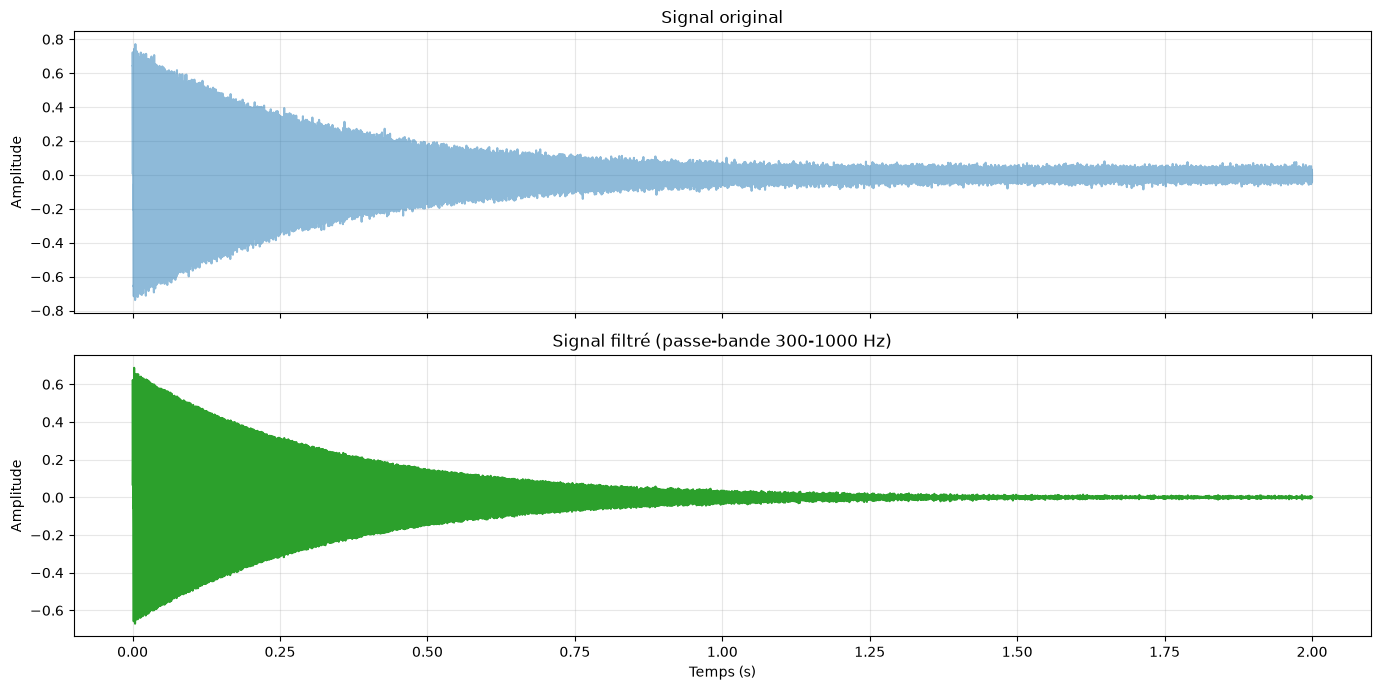

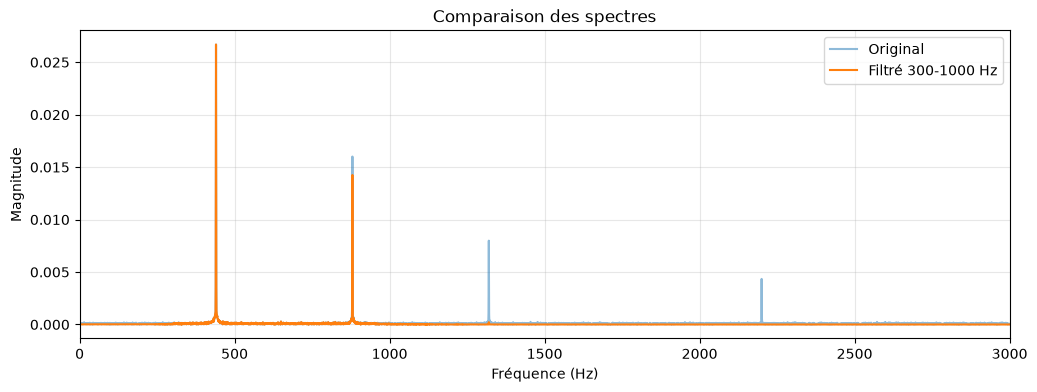

In [14]:
# Filtre passe-bande simple pour isoler une bande de fréquences
# Exemple : bande 300 - 1000 Hz
f_low, f_high = 300, 1000
b, a = signal.butter(4, [f_low, f_high], btype='band', fs=fs)
x_filtre = signal.filtfilt(b, a, x_audio)

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
axes[0].plot(t_audio, x_audio, color='C0', alpha=0.5)
axes[0].set_ylabel('Amplitude')
axes[0].set_title('Signal original')
axes[0].grid(alpha=0.3)

axes[1].plot(t_audio, x_filtre, color='C2')
axes[1].set_xlabel('Temps (s)')
axes[1].set_ylabel('Amplitude')
axes[1].set_title(f'Signal filtré (passe-bande {f_low}-{f_high} Hz)')
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Vérification : comparer les spectres
X_filtre = fft(x_filtre * window)
mag_filtre = 2 * np.abs(X_filtre[:N//2]) / N

plt.figure(figsize=(12, 4))
plt.plot(freqs_pos, mag_pos, alpha=0.5, label='Original')
plt.plot(freqs_pos, mag_filtre, label='Filtré 300-1000 Hz')
plt.xlim(0, min(3000, fs//2))
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Magnitude')
plt.title('Comparaison des spectres')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [15]:
# Écoute dans Jupyter
try:
    from IPython.display import Audio, display
    print("🎧 Signal ORIGINAL :")
    display(Audio(x_audio, rate=fs, normalize=True))
    print("\n🎧 Signal FILTRÉ (passe-bande) :")
    display(Audio(x_filtre, rate=fs, normalize=True))
except ImportError:
    print("⚠ IPython.display non disponible.")

🎧 Signal ORIGINAL :



🎧 Signal FILTRÉ (passe-bande) :


## Interprétation — Filtrage fréquentiel

### Effet du filtre passe-bande

- **Avant** : tout le contenu spectral est présent (basses ET hautes fréquences).
- **Après** : seules les fréquences 300–1000 Hz subsistent.
- Le spectre comparatif montre clairement la **suppression** des fréquences hors bande.

### Lien avec la transformée de Fourier

Un filtre passe-bande est un **système LTI** dont la réponse fréquentielle est :
$$ H(e^{j\omega}) = \begin{cases} 1 & \omega_{low} < |\omega| < \omega_{high} \\ 0 & \text{sinon} \end{cases} $$

En pratique, on utilise un filtre de Butterworth (transition douce) au lieu d'un filtre idéal (impossible à réaliser).

### Application : égaliseurs audio

Un égaliseur graphique à 10 bandes est composé de 10 filtres passe-bande en cascade. Le spectrogramme permet de **voir l'effet** en temps réel.

### Conclusion

> **La transformée de Fourier n'est pas qu'un outil d'analyse** : c'est aussi la base du **design de filtres** et de la **manipulation du contenu fréquentiel**.

# 6. Synthèse de la Semaine 6

## Pourquoi la transformée de Fourier ? — En une phrase

> **La transformée de Fourier projette un signal temporel sur une base de sinusoïdes, révélant son contenu fréquentiel — information invisible dans le domaine temporel.**

## Points clés retenus

1. **Série de Fourier** : décomposition d'un signal périodique en harmoniques.
2. **DTFT** : transformée continue pour signaux discrets.
3. **DFT/FFT** : version échantillonnée et algorithmiquement efficace.
4. **Résolution fréquentielle** : $\Delta f = f_s / N$ (fenêtre rectangulaire).
5. **Fenêtrage** : indispensable pour réduire les fuites spectrales.
6. **Spectrogramme (STFT)** : représentation temps-fréquence pour signaux non-stationnaires.
7. **Parseval** : conservation de l'énergie entre temps et fréquence.
8. **Symétrie** : pour signal réel, spectre symétrique (autour de 0 ou Nyquist).

## Choix de la fenêtre (récapitulatif)

| Besoin | Fenêtre |
|---|---|
| Résolution maximale | Rectangulaire |
| Usage général | **Hamming** |
| Mesure précise d'amplitude | Flat-top |
| Très faibles fuites | Blackman |

## Compromis temps-fréquence

$$ \Delta t \cdot \Delta f \geq \frac{1}{2} \quad \text{(inégalité de Gabor)} $$

Impossible d'avoir simultanément une excellente résolution temporelle et fréquentielle.

## Compétences acquises

- ✅ Synthétiser un signal par série de Fourier (carré, triangle)
- ✅ Calculer et interpréter une FFT
- ✅ Choisir et appliquer une fenêtre adaptée
- ✅ Construire un spectrogramme
- ✅ Détecter automatiquement des fréquences dominantes
- ✅ Analyser un signal audio réel
- ✅ Concevoir et appliquer un filtre passe-bande
- ✅ Lire un spectre de phase

## Pour aller plus loin

- **Wavelets (ondelettes)** : analyse temps-fréquence multi-résolution.
- **Transformée de Hilbert-Huang** : signaux non-linéaires.
- **Cepstre** : analyse de la structure harmonique des signaux vocaux.
- **Analyse spectrale paramétrique** : MUSIC, ESPRIT pour haute résolution.
- **Deep learning audio** : spectrogrammes en entrée de réseaux de neurones (Shazam, transcription musicale).

## Lien avec les semaines précédentes

| Semaine | Lien avec Fourier |
|---|---|
| 4 | La convolution devient multiplication dans le domaine fréquentiel |
| 5 | La TFTD est la transformée en Z évaluée sur le cercle unité |
| 6 | Application fréquentielle de tout ce qui précède |

## Lien avec les semaines suivantes

- **Semaine 8** : FFT et applications (filtrage fréquentiel, convolution rapide)
- **Semaine 9** : Filtres RIF/IIR optimisés (Butterworth, Chebyshev)
- **Semaine 10** : Applications temps-fréquence (STFT, ondelettes)

# 7. Livrable Semaine 6

- Remplir les cellules de code avec vos solutions.
- Répondre aux questions théoriques dans les cellules markdown.
- Inclure des commentaires explicatifs.
- Rendre le notebook complet (cellules exécutées).

**Checklist avant rendu** :
- [ ] Vérifier qu'aucune cellule ne produit d'erreur (`Kernel → Restart & Run All`)
- [ ] Toutes les **interprétations** sont présentes après chaque démo/exercice
- [ ] Les **spectres** et **spectrogrammes** sont lisibles (labels, légendes, titres)
- [ ] Vérifier la **cohérence théorique** (résolution, symétrie, Parseval)
- [ ] Comprendre le **rôle du fenêtrage** et savoir choisir une fenêtre
- [ ] Avoir **écouté** les résultats audio (si fichier audio utilisé)
- [ ] Exporter en PDF/HTML avec les sorties visibles

**Date de rendu** : à définir par l'enseignant.

---